# Hierarchical Multi-Model Comparison: Bayesian RL
We fit 3 models simultaneously across all participants using a hierarchical structure. 
1. **Single Alpha**: 1 global alpha, 1 global beta.
2. **Valence**: 2 alphas (PE>0 vs PE<=0), 1 global beta.
3. **Task**: 2 alphas (Win vs Lose domain), 2 betas (Win vs Lose domain).

Then we compare them using `az.compare` and plot the winning model for each individual.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

# Import custom hierarchical learning functions
from learning_functions import update_q_hierarchical, update_m2_hierarchical, update_m3_hierarchical

warnings.filterwarnings('ignore')


In [2]:
# Load Data
file_path = '../data/allsubs_combined.csv'
df = pd.read_csv(file_path)

# Filter out trials with missing choices
df = df.dropna(subset=['ChoiceKey']).reset_index(drop=True).copy()

# Map stimulus IDs to integers 0, 1, 2, 3
stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df['LeftID_int'] = df['LeftID'].map(stim_map)
df['RightID_int'] = df['RightID'].map(stim_map)
df['ChosenID_int'] = df['ChosenID'].map(stim_map)

# Map ChoiceKey to 0 (Left) and 1 (Right)
df['Choice'] = df['ChoiceKey'] - 1

# Scale rewards for more stable sampling
df['RewardScaled'] = df['TrialPoints'] / 30.0

# Indicator for Win trials
df['is_win_trial'] = (df['TrialType'] == 'W').astype(int)

# Create SubIdx (0 to n_sub-1)
unique_subs = df['Sub'].unique()
sub_idx_map = {sub: i for i, sub in enumerate(unique_subs)}
df['SubIdx'] = df['Sub'].map(sub_idx_map)
n_sub = len(unique_subs)

# Mark the first trial of each subject
df['is_first'] = 0
for sub in unique_subs:
    sub_indices = df[df['Sub'] == sub].index
    if len(sub_indices) > 0:
        df.loc[sub_indices[0], 'is_first'] = 1

print(f"Total subjects: {n_sub}")
print(f"Total trials across all subjects: {len(df)}")


Total subjects: 67
Total trials across all subjects: 6520


In [3]:
def make_hierarchical_alpha(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=1.5)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.invlogit(mu + raw * sigma))

def make_hierarchical_beta(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=2.0)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.exp(mu + raw * sigma))

def build_model_1(df, n_sub):
    """Model 1: Hierarchical Single Alpha, Single Beta"""
    with pm.Model() as m1:
        alpha = make_hierarchical_alpha('alpha', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        
        Q_init = pt.zeros((n_sub, 4))
        outputs_info = [Q_init, None, None, None]
        
        results, updates = pytensor.scan(
            fn=update_q_hierarchical,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=outputs_info,
            non_sequences=[alpha],
            strict=True
        )
        
        q_left_seq = results[1]
        q_right_seq = results[2]
        Q_reset_seq = results[3]
        
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        pm.Deterministic('Q_values_pre_update', Q_reset_seq[pt.arange(Q_reset_seq.shape[0]), sub_idx_seq, :])
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
    return m1

def build_model_2(df, n_sub):
    """Model 2: Hierarchical Valence (Alpha split by PE), Single Beta"""
    with pm.Model() as m2:
        alpha_pos = make_hierarchical_alpha('alpha_pos', n_sub)
        alpha_neg = make_hierarchical_alpha('alpha_neg', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        
        Q_init = pt.zeros((n_sub, 4))
        outputs_info = [Q_init, None, None, None]
        
        results, updates = pytensor.scan(
            fn=update_m2_hierarchical,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=outputs_info,
            non_sequences=[alpha_pos, alpha_neg],
            strict=True
        )
        
        q_left_seq = results[1]
        q_right_seq = results[2]
        Q_reset_seq = results[3]
        
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        pm.Deterministic('Q_values_pre_update', Q_reset_seq[pt.arange(Q_reset_seq.shape[0]), sub_idx_seq, :])
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
    return m2

def build_model_3(df, n_sub):
    """Model 3: Hierarchical Task (Alpha & Beta split by domain)"""
    with pm.Model() as m3:
        alpha_win = make_hierarchical_alpha('alpha_win', n_sub)
        alpha_lose = make_hierarchical_alpha('alpha_lose', n_sub)
        beta_win = make_hierarchical_beta('beta_win', n_sub)
        beta_lose = make_hierarchical_beta('beta_lose', n_sub)
        
        Q_init = pt.zeros((n_sub, 4))
        outputs_info = [Q_init, None, None, None]
        
        results, updates = pytensor.scan(
            fn=update_m3_hierarchical,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['is_win_trial'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=outputs_info,
            non_sequences=[alpha_win, alpha_lose],
            strict=True
        )
        
        q_left_seq = results[1]
        q_right_seq = results[2]
        Q_reset_seq = results[3]
        
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        pm.Deterministic('Q_values_pre_update', Q_reset_seq[pt.arange(Q_reset_seq.shape[0]), sub_idx_seq, :])
        is_win_seq = pt.as_tensor_variable(df['is_win_trial'].values)
        
        beta_seq = pt.switch(is_win_seq, beta_win[sub_idx_seq], beta_lose[sub_idx_seq])
        p_right_raw = pm.math.sigmoid(beta_seq * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
    return m3


In [4]:
import xarray as xr
def fast_add_bernoulli_ll(idata, y_obs):
    p = idata.posterior['p_right']
    y = xr.DataArray(y_obs, dims=[p.dims[-1]])
    ll = (np.log(p) * y + np.log(1.0 - p) * (1.0 - y)).transpose("chain", "draw", ...)
    idata.add_groups(log_likelihood={'choice_obs': ll})

# Fit models on full population
print("--- Building and Sampling Model 1 ---")
m1 = build_model_1(df, n_sub)
with m1:
    idata_1 = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
    fast_add_bernoulli_ll(idata_1, df['Choice'].values)

print("--- Building and Sampling Model 2 ---")
m2 = build_model_2(df, n_sub)
with m2:
    idata_2 = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
    fast_add_bernoulli_ll(idata_2, df['Choice'].values)

print("--- Building and Sampling Model 3 ---")
m3 = build_model_3(df, n_sub)
with m3:
    idata_3 = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
    fast_add_bernoulli_ll(idata_3, df['Choice'].values)




--- Building and Sampling Model 1 ---


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

--- Building and Sampling Model 2 ---


... (8 outputs left out)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


In [5]:
# Model Comparison
comp_dict = {
    "1. single alpha": idata_1,
    "2. valence": idata_2,
    "3. task": idata_3
}
comp = az.compare(comp_dict)
print("\nOverall Model Comparison (LOO):")
display(comp)


Overall Model Comparison (LOO):


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
2. valence,0,-2907.078079,149.683315,0.000000,0.494644,43.985374,0.000000,True,log
3. task,1,-2907.657903,164.252153,0.579824,0.477469,43.474016,10.662607,True,log
1. single alpha,2,-2933.124816,108.118560,26.046737,0.027886,43.692127,8.782032,True,log


Plotting results for winning model: 2. valence


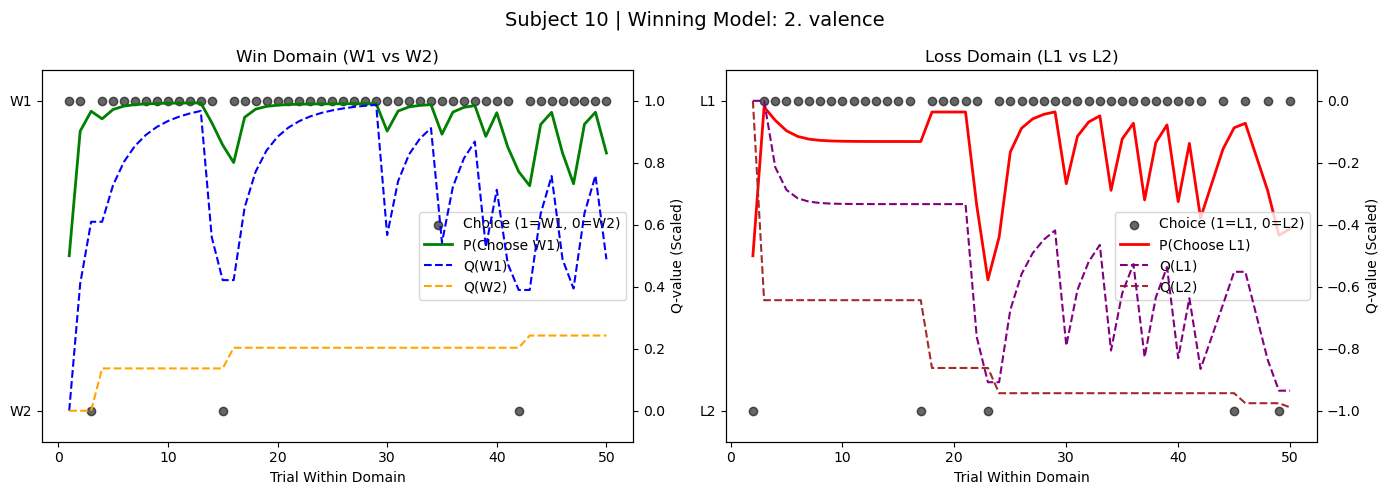

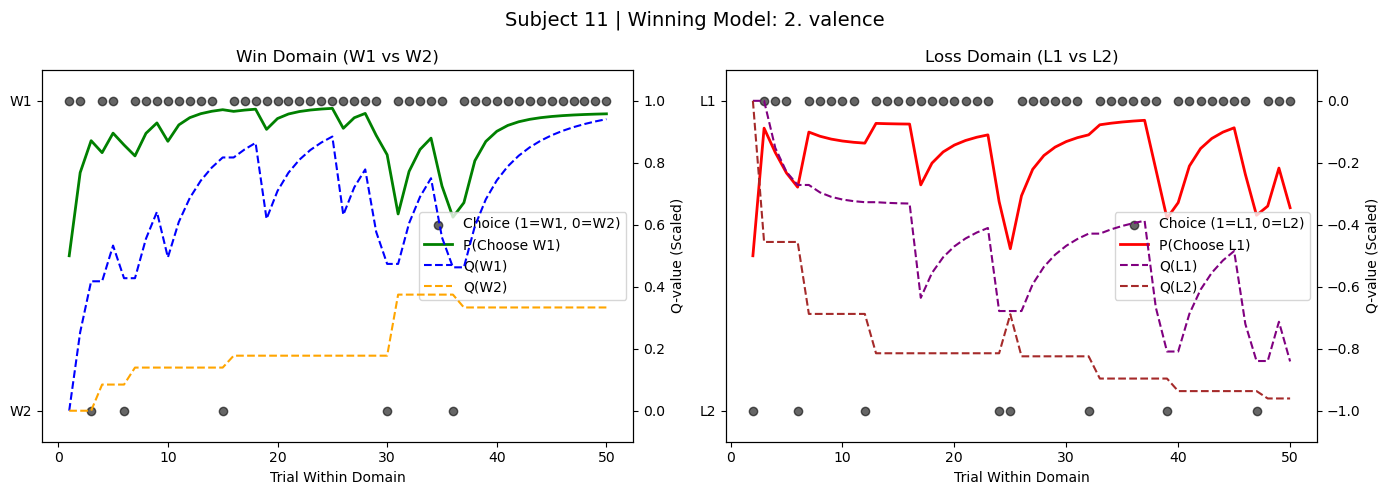

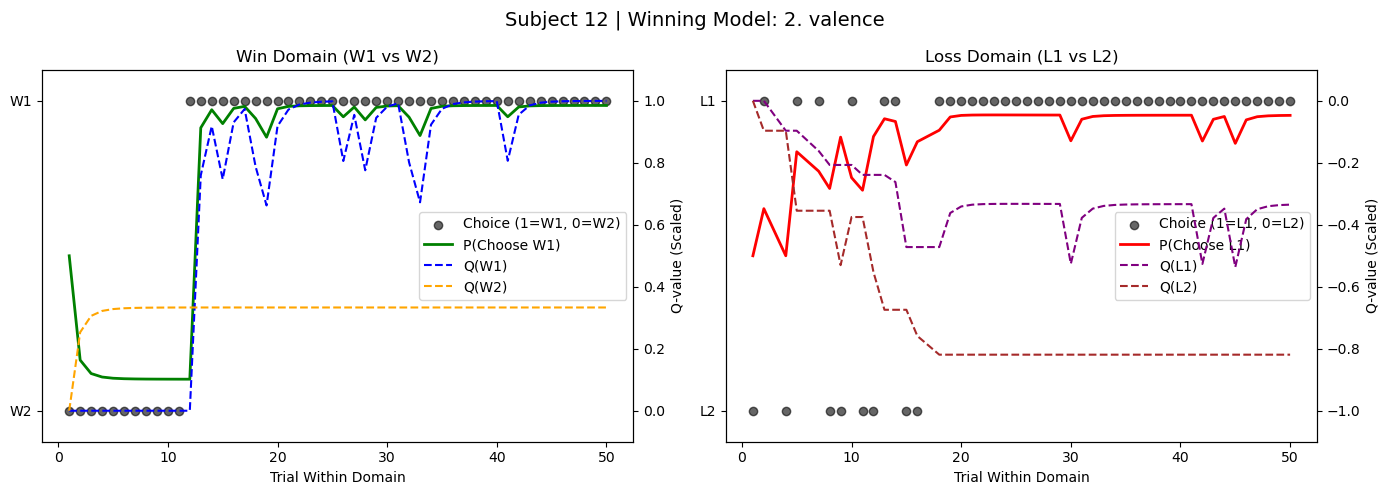

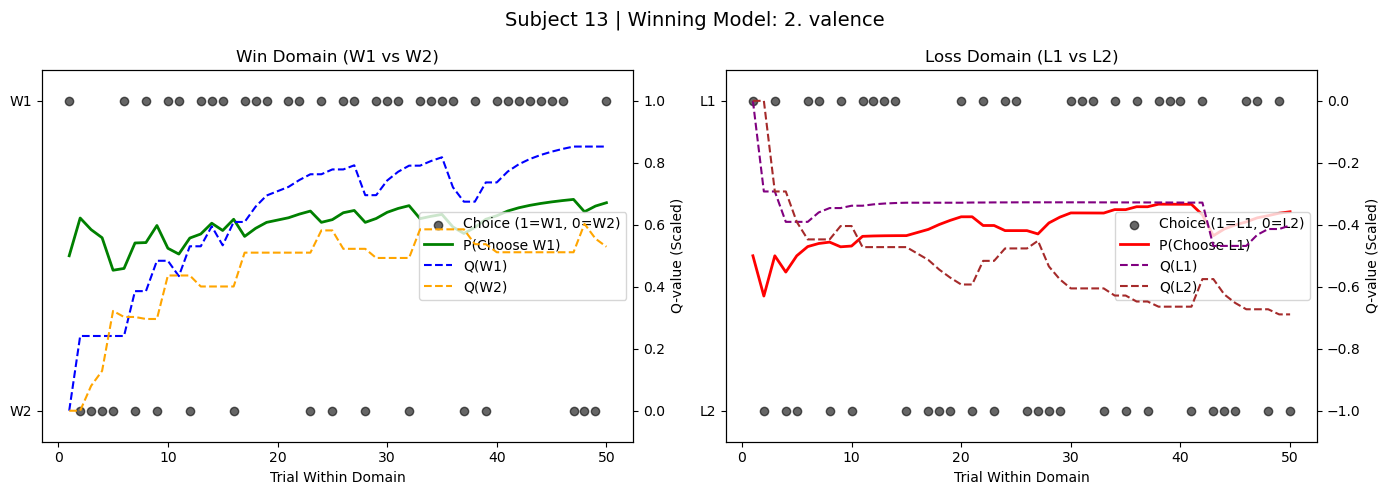

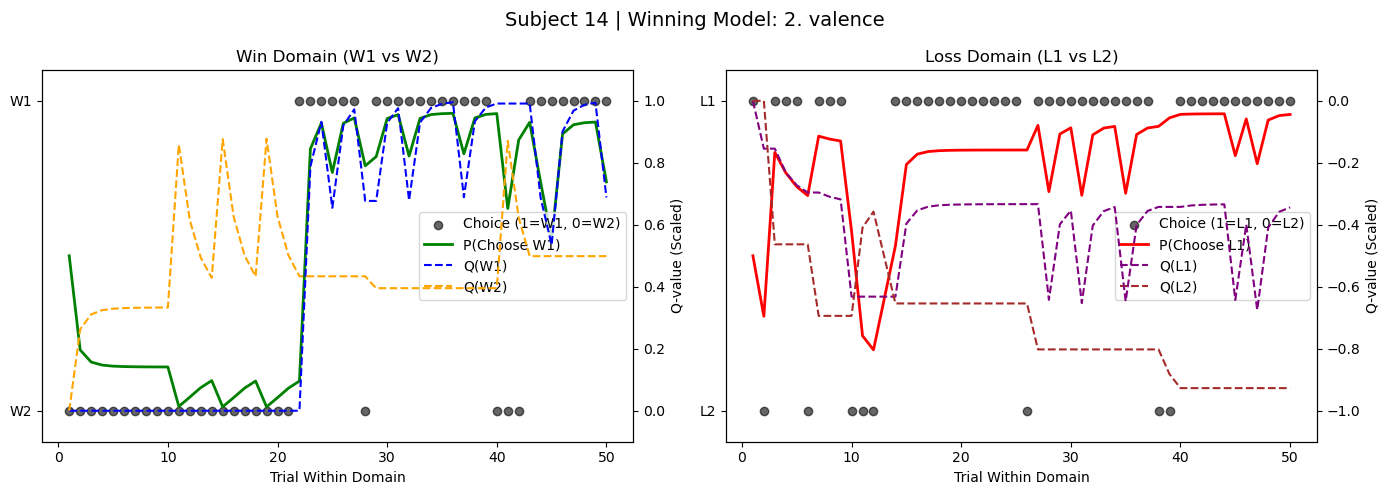

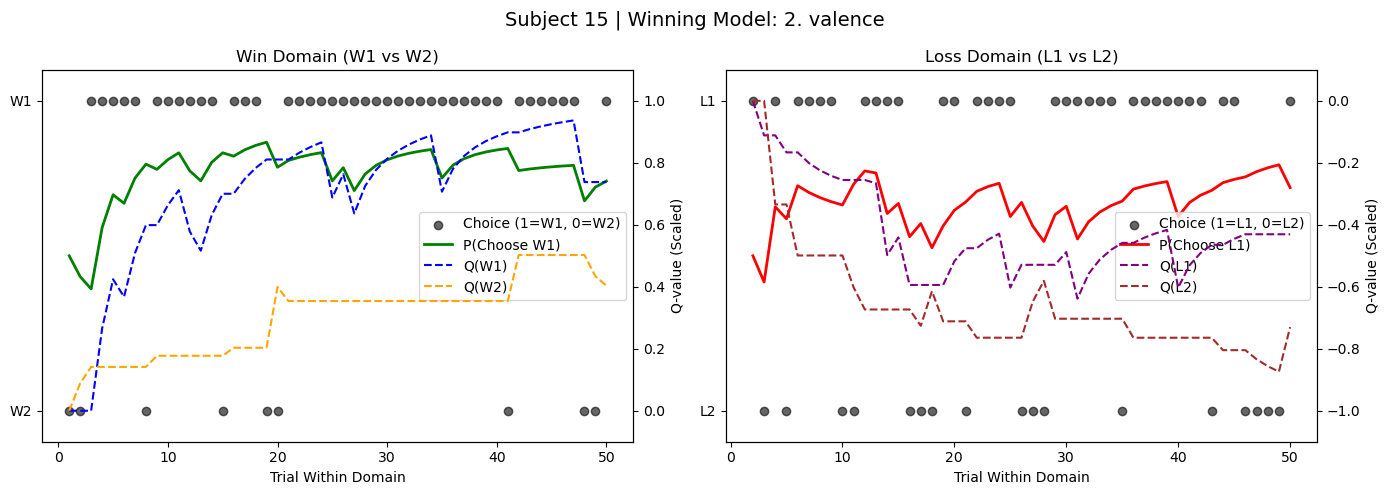

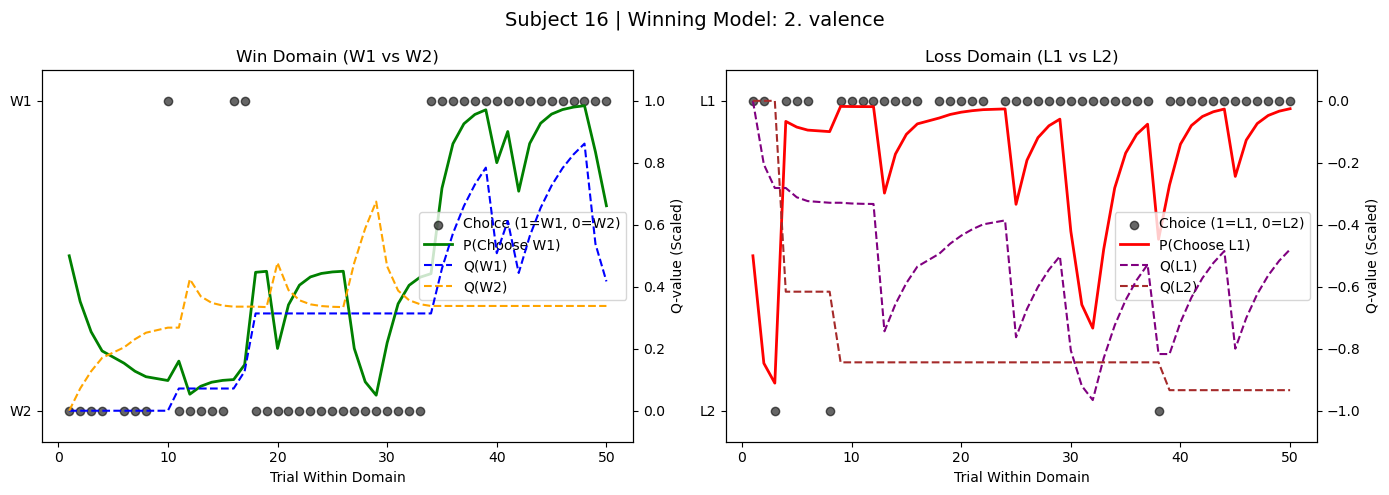

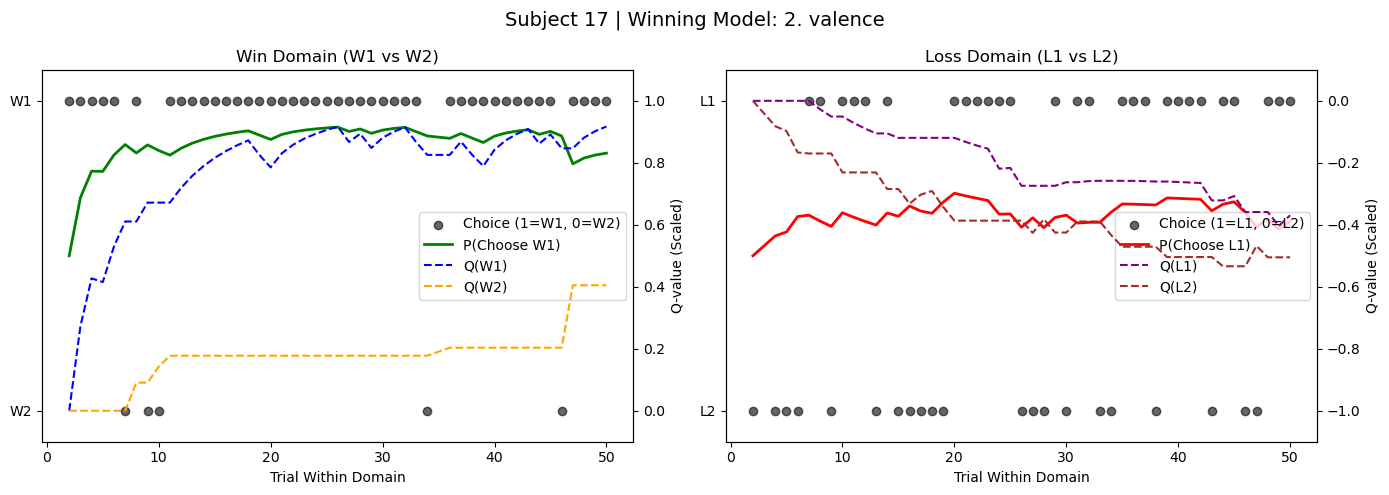

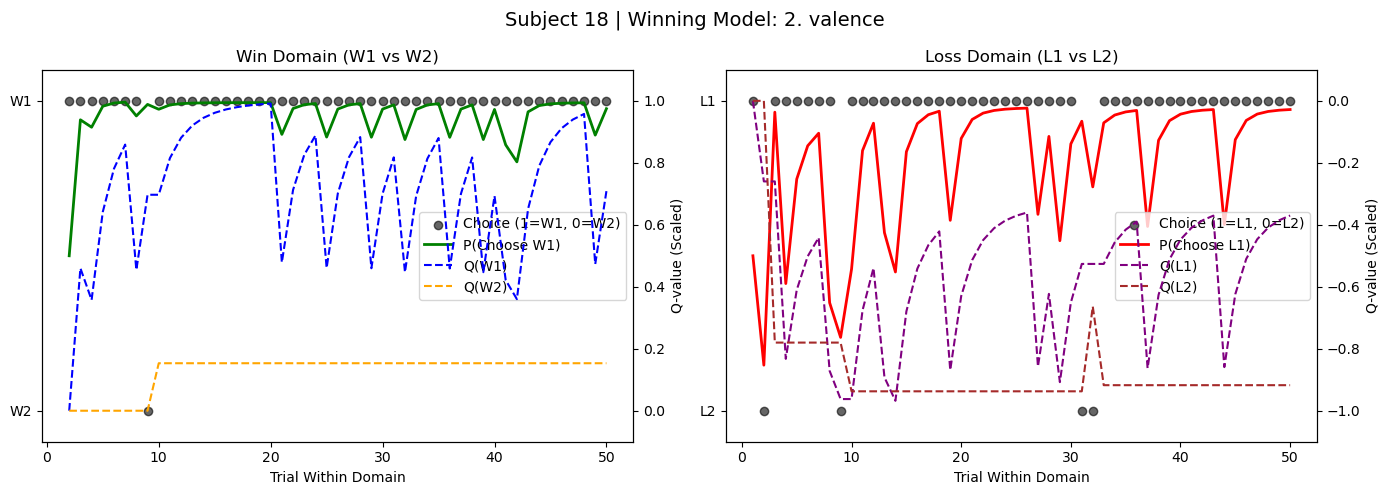

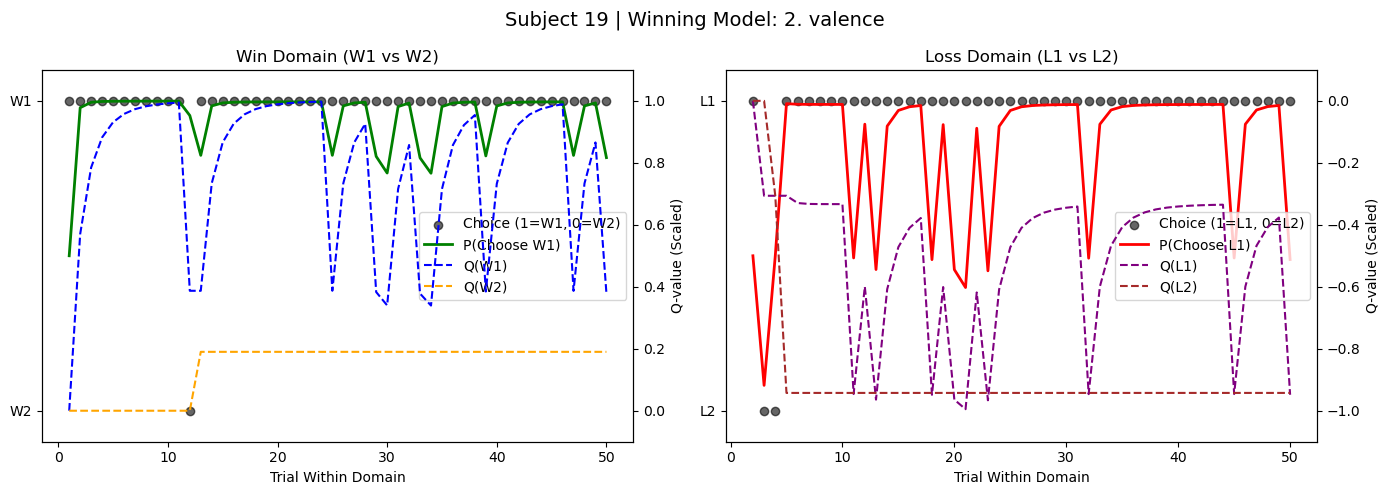

In [6]:
def get_p_opt1(row, opt1_id):
    if row['RightID'] == opt1_id:
        return row['P_Right']
    elif row['LeftID'] == opt1_id:
        return 1.0 - row['P_Right']
    return np.nan

def plot_winning_model(df, idata, model_name, n_sub):
    """
    Plots the winning model's fit for each participant.
    """
    Q_mean = idata.posterior['Q_values_pre_update'].mean(dim=['chain', 'draw']).values
    p_right_mean = idata.posterior['p_right'].mean(dim=['chain', 'draw']).values
    
    df = df.copy()
    df['P_Right'] = p_right_mean
    df['P_W1'] = df.apply(lambda r: get_p_opt1(r, 'W1') if r['TrialType'] == 'W' else np.nan, axis=1)
    df['P_L1'] = df.apply(lambda r: get_p_opt1(r, 'L1') if r['TrialType'] == 'L' else np.nan, axis=1)
    
    unique_subs = df['Sub'].unique()
    
    for sub in unique_subs[:10]: # Plotting only top 3 as example
        df_sub = df[df['Sub'] == sub].copy()
        sub_idx = df_sub['SubIdx'].iloc[0]
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
        fig.suptitle(f"Subject {sub} | Winning Model: {model_name}", fontsize=14)
        
        # Win Domain
        ax_w = axes[0]
        df_w = df_sub[df_sub['TrialType'] == 'W']
        if not df_w.empty:
            x_w = df_w['IdxWithinType'].values
            choices_w = (df_w['ChosenID'] == 'W1').astype(int).values
            ax_w.scatter(x_w, choices_w, color='black', alpha=0.6, label='Choice (1=W1, 0=W2)')
            ax_w.plot(x_w, df_w['P_W1'].values, color='green', label='P(Choose W1)', lw=2)
            
            ax_w.set_title("Win Domain (W1 vs W2)")
            ax_w.set_xlabel("Trial Within Domain")
            ax_w.set_yticks([0, 1])
            ax_w.set_yticklabels(['W2', 'W1'])
            ax_w.set_ylim(-0.1, 1.1)
            
            ax_qw = ax_w.twinx()
            ax_qw.plot(x_w, Q_mean[df_w.index, 0], color='blue', linestyle='--', label='Q(W1)')
            ax_qw.plot(x_w, Q_mean[df_w.index, 1], color='orange', linestyle='--', label='Q(W2)')
            ax_qw.set_ylabel("Q-value (Scaled)")
            ax_qw.set_ylim(-0.1, 1.1)
            
            lines, labels = ax_w.get_legend_handles_labels()
            lines2, labels2 = ax_qw.get_legend_handles_labels()
            ax_w.legend(lines + lines2, labels + labels2, loc='center right')
            
        # Lose Domain
        ax_l = axes[1]
        df_l = df_sub[df_sub['TrialType'] == 'L']
        if not df_l.empty:
            x_l = df_l['IdxWithinType'].values
            choices_l = (df_l['ChosenID'] == 'L1').astype(int).values
            ax_l.scatter(x_l, choices_l, color='black', alpha=0.6, label='Choice (1=L1, 0=L2)')
            ax_l.plot(x_l, df_l['P_L1'].values, color='red', label='P(Choose L1)', lw=2)
            
            ax_l.set_title("Loss Domain (L1 vs L2)")
            ax_l.set_xlabel("Trial Within Domain")
            ax_l.set_yticks([0, 1])
            ax_l.set_yticklabels(['L2', 'L1'])
            ax_l.set_ylim(-0.1, 1.1)
            
            ax_ql = ax_l.twinx()
            ax_ql.plot(x_l, Q_mean[df_l.index, 2], color='purple', linestyle='--', label='Q(L1)')
            ax_ql.plot(x_l, Q_mean[df_l.index, 3], color='brown', linestyle='--', label='Q(L2)')
            ax_ql.set_ylabel("Q-value (Scaled)")
            ax_ql.set_ylim(-1.1, 0.1)
            
            lines, labels = ax_l.get_legend_handles_labels()
            lines2, labels2 = ax_ql.get_legend_handles_labels()
            ax_l.legend(lines + lines2, labels + labels2, loc='center right')
            
        plt.tight_layout()
        plt.show()

# Plot winner
winning_model_name = comp.index[0]
winning_idata = comp_dict[winning_model_name]
print(f"Plotting results for winning model: {winning_model_name}")
plot_winning_model(df, winning_idata, winning_model_name, n_sub)
